In [1]:
#Imports and settings

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

DATA = "../data/diabetic_data.csv"   # <-- path to your file
SEED = 42

In [3]:
#Load and clean the data

In [4]:
df = pd.read_csv(DATA, na_values="?", low_memory=False)
print(f"Hospital stays in the file: {len(df):,}")

# Remove patients who died or went to hospice (they cannot be readmitted), and invalid gender
DEATH_OR_HOSPICE = {11, 13, 14, 19, 20, 21}
df = df[~df["discharge_disposition_id"].isin(DEATH_OR_HOSPICE)]
df = df[df["gender"].isin(["Male", "Female"])].reset_index(drop=True)

y = (df["readmitted"] == "<30").astype(int).to_numpy()   # 1 = readmitted within 30 days
groups = df["patient_nbr"].to_numpy()                    # patient ID

print(f"Hospital stays after cleaning: {len(df):,}")
print(f"Different patients: {len(np.unique(groups)):,}")
print(f"Readmitted within 30 days: {y.sum():,} stays ({y.mean():.1%})")

Hospital stays in the file: 101,766
Hospital stays after cleaning: 99,340
Different patients: 69,987
Readmitted within 30 days: 11,314 stays (11.4%)


In [5]:
#Build the information the model can use

In [6]:
MED_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
            "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
            "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
            "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone",
            "metformin-pioglitazone"]

def diagnosis_group(code):
    """Map an ICD-9 diagnosis code to a clinical group."""
    if pd.isna(code):
        return "other"
    code = str(code)
    if code[0] in "VE":
        return "other"
    try:
        c = float(code)
    except ValueError:
        return "other"
    if 250 <= c < 251: return "diabetes"
    if 390 <= c <= 459 or c == 785: return "circulatory"
    if 460 <= c <= 519 or c == 786: return "respiratory"
    if 520 <= c <= 579 or c == 787: return "digestive"
    if 800 <= c <= 999: return "injury"
    if 710 <= c <= 739: return "musculoskeletal"
    if 580 <= c <= 629 or c == 788: return "genitourinary"
    if 140 <= c <= 239: return "neoplasms"
    return "other"

def discharge_group(d):
    if d == 1: return "home"
    if d in (6, 8): return "home_health"
    if d in (2, 3, 4, 5, 15, 22, 23, 24, 27, 28, 29, 30): return "facility"
    return "other"

X = pd.DataFrame(index=df.index)

# Numbers
X["age"] = df["age"].astype(str).str.extract(r"\[(\d+)-")[0].astype(float) + 5   # middle of the age band
for c in ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
          "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]:
    X[c] = df[c].astype(float)
meds = df[[c for c in MED_COLS if c in df.columns]].astype(str)
X["n_diabetes_meds"] = (meds != "No").sum(axis=1).astype(float)
X["n_dose_changes"] = meds.isin(["Up", "Down"]).sum(axis=1).astype(float)

# Yes/no facts
X["emergency_admission"] = (df["admission_type_id"] == 1).astype(int)
X["insulin"] = (df["insulin"].astype(str) != "No").astype(int)
X["med_change"] = (df["change"].astype(str) == "Ch").astype(int)
X["on_diabetes_med"] = (df["diabetesMed"].astype(str) == "Yes").astype(int)
a1c = df["A1Cresult"].fillna("None").astype(str)
X["a1c_measured"] = (a1c != "None").astype(int)
X["a1c_high"] = a1c.isin([">7", ">8"]).astype(int)
X["glucose_high"] = df["max_glu_serum"].fillna("None").astype(str).isin([">200", ">300"]).astype(int)
disch = df["discharge_disposition_id"].map(discharge_group)
for g in ["home", "home_health", "facility"]:
    X[f"discharge_{g}"] = (disch == g).astype(int)
diag = df["diag_1"].map(diagnosis_group)
for g in ["diabetes", "circulatory", "respiratory", "digestive", "injury",
          "musculoskeletal", "genitourinary", "neoplasms"]:
    X[f"diag_{g}"] = (diag == g).astype(int)

# Readable names, used whenever a rule is shown
LABELS = {
    "number_inpatient": "Inpatient admissions (past year)",
    "number_emergency": "Emergency visits (past year)",
    "number_outpatient": "Outpatient visits (past year)",
    "number_diagnoses": "Number of diagnoses",
    "num_medications": "Medications during stay",
    "num_lab_procedures": "Lab tests during stay",
    "num_procedures": "Procedures during stay",
    "time_in_hospital": "Length of stay (days)",
    "n_diabetes_meds": "Diabetes medications",
    "n_dose_changes": "Diabetes dose changes",
    "emergency_admission": "Emergency admission",
    "on_diabetes_med": "On diabetes medication",
    "med_change": "Medication changed during stay",
    "insulin": "On insulin",
    "a1c_measured": "HbA1c measured",
    "a1c_high": "HbA1c high",
    "glucose_high": "Glucose high",
    "discharge_home_health": "Discharged with home health care",
    "discharge_facility": "Discharged to a care facility",
    "discharge_home": "Discharged home",
    "age": "Age",
}

def pretty(text):
    """Replace column names in a rule with readable names."""
    for name in sorted(LABELS, key=len, reverse=True):
        text = text.replace(name, LABELS[name])
    return text.replace("diag_", "Main diagnosis: ")

YES_NO = [c for c in X.columns if set(X[c].unique()) <= {0, 1}]
NUMBERS = [c for c in X.columns if c not in YES_NO]
print(f"Pieces of information per stay: {X.shape[1]} ({len(NUMBERS)} numbers, {len(YES_NO)} yes/no facts)")
X.head()

Pieces of information per stay: 29 (11 numbers, 18 yes/no facts)


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,n_diabetes_meds,...,discharge_home_health,discharge_facility,diag_diabetes,diag_circulatory,diag_respiratory,diag_digestive,diag_injury,diag_musculoskeletal,diag_genitourinary,diag_neoplasms
0,5.0,1.0,41.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0,0,1,0,0,0,0,0,0,0
1,15.0,3.0,59.0,0.0,18.0,0.0,0.0,0.0,9.0,1.0,...,0,0,0,0,0,0,0,0,0,0
2,25.0,2.0,11.0,5.0,13.0,2.0,0.0,1.0,6.0,1.0,...,0,0,0,0,0,0,0,0,0,0
3,35.0,2.0,44.0,1.0,16.0,0.0,0.0,0.0,7.0,1.0,...,0,0,0,0,0,0,0,0,0,0
4,45.0,1.0,51.0,0.0,8.0,0.0,0.0,0.0,5.0,2.0,...,0,0,0,0,0,0,0,0,0,1


In [7]:
#Split into training, validation and test

In [8]:
# Test group: 20% of patients, kept aside until the very end
split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr, te = next(split.split(X, y, groups))

# Validation group: 20% of the training patients, used only to choose the model's settings
split_val = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
fit_part, val_part = next(split_val.split(X.iloc[tr], y[tr], groups[tr]))
fit_idx, val_idx = tr[fit_part], tr[val_part]

Xtr, Xte, ytr, yte = X.iloc[tr], X.iloc[te], y[tr], y[te]
print(f"Training stays: {len(tr):,} (of which {len(val_idx):,} are used for validation) | Test stays: {len(te):,}")
print("Patients in both training and test:", len(set(groups[tr]) & set(groups[te])), "(must be 0)")
print("Patients in both fitting and validation:", len(set(groups[fit_idx]) & set(groups[val_idx])), "(must be 0)")

Training stays: 79,567 (of which 15,962 are used for validation) | Test stays: 19,773
Patients in both training and test: 0 (must be 0)
Patients in both fitting and validation: 0 (must be 0)


In [9]:
#Turn numbers into yes/no conditions

In [10]:
# Turn every number into simple yes/no conditions such as "Length of stay >= 7".
# The cut points come from the training patients only.
cuts = {}
for c in NUMBERS:
    qs = np.unique(np.quantile(Xtr[c], [0.25, 0.5, 0.75, 0.9]))
    cuts[c] = [q for q in qs if Xtr[c].min() < q <= Xtr[c].max()]

def to_conditions(X):
    B = pd.DataFrame(index=X.index)
    for c in X.columns:
        if c in cuts:
            for t in cuts[c]:
                B[f"{c} >= {t:g}"] = (X[c] >= t).astype(int)
        else:
            B[c] = X[c]
    return B

B = to_conditions(X)
Btr, Bte = B.loc[Xtr.index], B.loc[Xte.index]
print(f"Candidate conditions the model can choose from: {B.shape[1]}")

Candidate conditions the model can choose from: 47


In [11]:
#The model, a points score learned from the data

In [12]:
def learn_points(B_fit, y_fit, max_items, max_points=5):
    """Learn a points score: keep at most max_items conditions and give each whole-number points."""
    coef = None
    for C in np.logspace(-4, 0, 25):
        m = LogisticRegression(penalty="l1", solver="liblinear", C=C).fit(B_fit, y_fit)
        if 0 < np.count_nonzero(m.coef_) <= max_items:
            coef = m.coef_.ravel()
    pts = np.round(coef / np.abs(coef).max() * max_points).astype(int)
    pts = pd.Series(pts, index=B_fit.columns)
    return pts[pts != 0]

# Use the validation patients to choose how many conditions the score should have
tried = []
for k in [4, 6, 8, 10, 12, 15]:
    pts = learn_points(B.loc[X.index[fit_idx]], y[fit_idx], k)
    val_score = (B.loc[X.index[val_idx], pts.index] @ pts).to_numpy(float)
    tried.append({"Maximum conditions": k, "Conditions kept": len(pts),
                  "Validation AUC-ROC": round(roc_auc_score(y[val_idx], val_score), 4)})
tried = pd.DataFrame(tried)
print("CHOOSING THE SIZE OF THE SCORE (higher validation AUC-ROC is better)")
print(tried.to_string(index=False))
BEST_K = int(tried.loc[tried["Validation AUC-ROC"].idxmax(), "Maximum conditions"])
print(f"\nChosen size: at most {BEST_K} conditions")

# Final model: learn the points again from all training patients with the chosen size
points = learn_points(Btr, ytr, BEST_K)
score_tr = (Btr[points.index] @ points).to_numpy(float)
score_te = (Bte[points.index] @ points).to_numpy(float)

# Turn the score into a probability of readmission
to_risk = LogisticRegression().fit(score_tr.reshape(-1, 1), ytr)
risk_tr = to_risk.predict_proba(score_tr.reshape(-1, 1))[:, 1]
risk_te = to_risk.predict_proba(score_te.reshape(-1, 1))[:, 1]

# Cut-off: roughly the highest-scoring quarter of training patients is flagged as high risk
CUTOFF = np.ceil(np.quantile(score_tr, 0.75))
pred_te = (score_te >= CUTOFF).astype(int)

points_table = pd.DataFrame({"Condition": [pretty(c) for c in points.index], "Points": points.values})
points_table = points_table.sort_values("Points", ascending=False).reset_index(drop=True)
print("\nHOW THE SCORE WORKS (add the points for every condition that is true for the patient)")
print(points_table.to_string(index=False))

risk_table = pd.DataFrame({"Score": np.arange(score_tr.min(), score_tr.max() + 1)})
risk_table["Chance of readmission"] = [f"{p:.1%}" for p in to_risk.predict_proba(risk_table[["Score"]].to_numpy(float))[:, 1]]
risk_table["Score"] = risk_table["Score"].astype(int)
print("\nWHAT EACH SCORE MEANS")
print(risk_table.to_string(index=False))
print(f"\nPatients with a score of {CUTOFF:.0f} or more are flagged as HIGH RISK.")

CHOOSING THE SIZE OF THE SCORE (higher validation AUC-ROC is better)
 Maximum conditions  Conditions kept  Validation AUC-ROC
                  4                3              0.6321
                  6                4              0.6389
                  8                4              0.6389
                 10                6              0.6343
                 12                6              0.6343
                 15                7              0.6408

Chosen size: at most 15 conditions

HOW THE SCORE WORKS (add the points for every condition that is true for the patient)
                            Condition  Points
Inpatient admissions (past year) >= 2       5
Inpatient admissions (past year) >= 1       4
        Discharged to a care facility       2
    Emergency visits (past year) >= 1       1
                      Discharged home      -3

WHAT EACH SCORE MEANS
 Score Chance of readmission
    -3                  7.1%
    -2                  7.9%
    -1                 

In [13]:
#The IF-THEN rules

In [14]:
# IF-THEN rules: a small decision tree, with its size chosen on the validation patients
best_leaves, best_auc = None, -1
for leaves in [4, 6, 8, 12, 16]:
    t = DecisionTreeClassifier(max_leaf_nodes=leaves, min_samples_leaf=200, random_state=0)
    t.fit(X.iloc[fit_idx], y[fit_idx])
    auc = roc_auc_score(y[val_idx], t.predict_proba(X.iloc[val_idx])[:, 1])
    if auc > best_auc:
        best_leaves, best_auc = leaves, auc
tree = DecisionTreeClassifier(max_leaf_nodes=best_leaves, min_samples_leaf=200, random_state=0).fit(Xtr, ytr)
tree_risk_te = tree.predict_proba(Xte)[:, 1]
BASE_RATE = ytr.mean()

def rule_text(steps):
    """Turn the tree's steps (column, cut point, above?) into short, non-repeating conditions."""
    low, high, yesno, order = {}, {}, {}, []
    for f, thr, above in steps:
        if f not in order:
            order.append(f)
        if f in YES_NO:
            yesno[f] = "Yes" if above else "No"
        elif above:
            low[f] = max(low.get(f, -np.inf), int(np.floor(thr)) + 1)    # counts are whole numbers
        else:
            high[f] = min(high.get(f, np.inf), int(np.floor(thr)))
    out = []
    for f in order:
        if f in yesno:
            out.append(f"{f} = {yesno[f]}")
        elif f in low and f in high:
            out.append(f"{f} = {low[f]}" if low[f] == high[f] else f"{f} between {low[f]} and {high[f]}")
        elif f in low:
            out.append(f"{f} >= {low[f]}")
        else:
            out.append(f"{f} = 0" if high[f] == 0 else f"{f} <= {high[f]}")
    return [pretty(c) for c in out]

leaf_stats = pd.Series(ytr).groupby(tree.apply(Xtr)).agg(["mean", "size"])

def all_rules():
    t, names, out = tree.tree_, list(X.columns), []
    def walk(node, conds):
        if t.children_left[node] == -1:
            out.append((leaf_stats.loc[node, "mean"], leaf_stats.loc[node, "size"], conds))
            return
        f, thr = names[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], conds + [(f, thr, False)])
        walk(t.children_right[node], conds + [(f, thr, True)])
    walk(0, [])
    return sorted(out, key=lambda r: -r[0])

print(f"THE {tree.get_n_leaves()} RULES, FROM HIGHEST TO LOWEST RISK   (average patient: {BASE_RATE:.1%} readmitted)\n")
rule_lines = []
for n, (risk, size, conds) in enumerate(all_rules(), start=1):
    text = (f"Rule {n}: IF " + "\n        AND ".join(rule_text(conds))
            + f"\n        THEN {risk:.1%} were readmitted ({size:,} training patients, {risk / BASE_RATE:.1f}x the average)")
    rule_lines.append(text)
    print(text + "\n")

THE 16 RULES, FROM HIGHEST TO LOWEST RISK   (average patient: 11.4% readmitted)

Rule 1: IF Inpatient admissions (past year) >= 5
        AND Emergency visits (past year) >= 1
        THEN 42.2% were readmitted (716 training patients, 3.7x the average)

Rule 2: IF Inpatient admissions (past year) >= 5
        AND Emergency visits (past year) = 0
        AND Age <= 70
        THEN 36.2% were readmitted (567 training patients, 3.2x the average)

Rule 3: IF Inpatient admissions (past year) >= 5
        AND Emergency visits (past year) = 0
        AND Age >= 71
        THEN 26.9% were readmitted (331 training patients, 2.4x the average)

Rule 4: IF Inpatient admissions (past year) = 1
        AND Discharged to a care facility = Yes
        AND Age <= 80
        AND Number of diagnoses <= 8
        THEN 23.1% were readmitted (732 training patients, 2.0x the average)

Rule 5: IF Inpatient admissions (past year) between 3 and 4
        THEN 21.4% were readmitted (3,906 training patients, 1.9x

In [15]:
#Results, as numbers and in plain words

In [16]:
def all_metrics(y_true, pred, risk):
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall (sensitivity)": recall_score(y_true, pred),
            "Specificity": tn / (tn + fp),
            "F1 score": f1_score(y_true, pred),
            "AUC-ROC": roc_auc_score(y_true, risk)}

tn, fp, fn, tp = confusion_matrix(yte, pred_te).ravel()
metrics = all_metrics(yte, pred_te, risk_te)
results = pd.DataFrame({"Metric": list(metrics), "Value": [round(v, 3) for v in metrics.values()]})
results.to_csv("../results/model2_results.csv", index=False)
with open("../results/model2_rules.txt", "w") as f:
    f.write("POINTS SCORE\n" + points_table.to_string(index=False) + "\n\nSCORE TO RISK\n"
            + risk_table.to_string(index=False) + "\n\nIF-THEN RULES\n" + "\n\n".join(rule_lines) + "\n")

print("RESULTS ON THE TEST PATIENTS")
print(results.to_string(index=False))

print("\nIN PLAIN WORDS")
print(f"- The model was tested on {len(yte):,} hospital stays it had never seen.")
print(f"- {yte.sum():,} of them really were readmitted within 30 days.")
print(f"- The model flagged {tp + fp:,} stays as high risk.")
print(f"- {tp:,} of those flagged were really readmitted (precision {metrics['Precision']:.0%}).")
print(f"- So it caught {tp:,} of the {yte.sum():,} real readmissions (recall {metrics['Recall (sensitivity)']:.0%}) and missed {fn:,}.")
print(f"- It raised {fp:,} false alarms on patients who were not readmitted.")
print(f"- AUC-ROC is {metrics['AUC-ROC']:.2f}. 0.50 means guessing, 1.00 means perfect.")
print(f"- The whole model is {len(points)} conditions with points, so anyone can check a prediction by hand.")
print(f"\nNote: {1 - yte.mean():.0%} of stays are not readmitted, so a model that flags nobody would")
print("already be that accurate. Judge the model by recall, precision and AUC-ROC, not accuracy alone.")

RESULTS ON THE TEST PATIENTS
              Metric  Value
            Accuracy  0.650
           Precision  0.178
Recall (sensitivity)  0.574
         Specificity  0.660
            F1 score  0.271
             AUC-ROC  0.648

IN PLAIN WORDS
- The model was tested on 19,773 hospital stays it had never seen.
- 2,244 of them really were readmitted within 30 days.
- The model flagged 7,255 stays as high risk.
- 1,289 of those flagged were really readmitted (precision 18%).
- So it caught 1,289 of the 2,244 real readmissions (recall 57%) and missed 955.
- It raised 5,966 false alarms on patients who were not readmitted.
- AUC-ROC is 0.65. 0.50 means guessing, 1.00 means perfect.
- The whole model is 5 conditions with points, so anyone can check a prediction by hand.

Note: 89% of stays are not readmitted, so a model that flags nobody would
already be that accurate. Judge the model by recall, precision and AUC-ROC, not accuracy alone.


In [17]:
#Charts

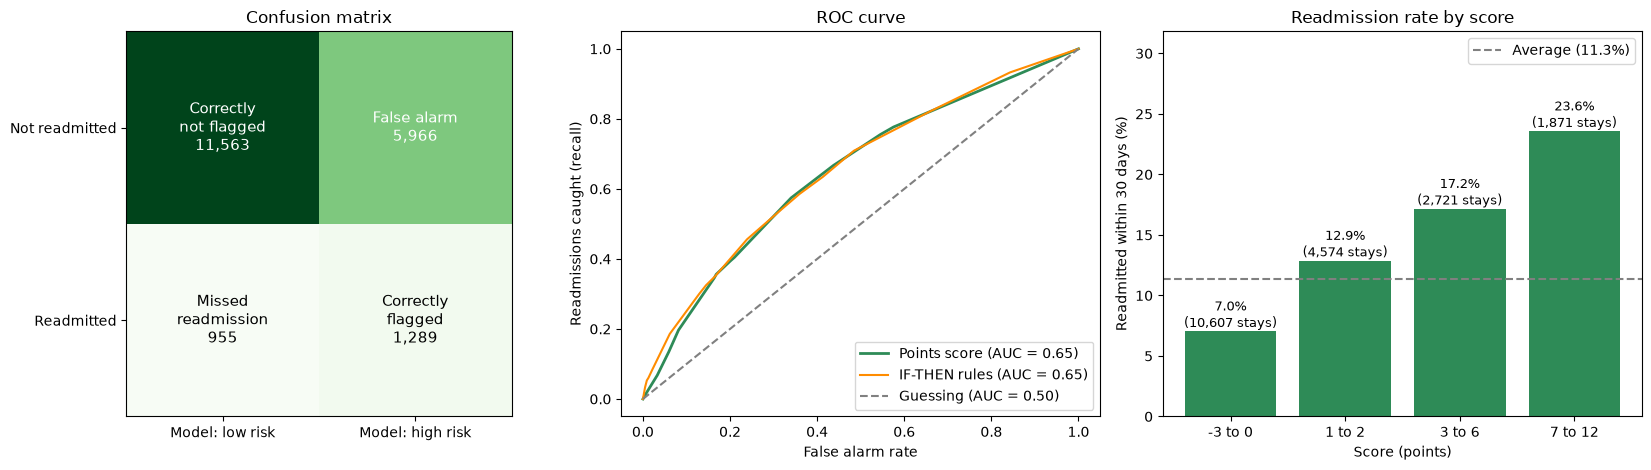

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Chart 1: confusion matrix
ax = axes[0]
cm = np.array([[tn, fp], [fn, tp]])
ax.imshow(cm, cmap="Greens")
names = [["Correctly\nnot flagged", "False alarm"], ["Missed\nreadmission", "Correctly\nflagged"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{names[i][j]}\n{cm[i, j]:,}", ha="center", va="center", fontsize=11,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Model: low risk", "Model: high risk"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Not readmitted", "Readmitted"])
ax.set_title("Confusion matrix")

# Chart 2: ROC curve
ax = axes[1]
f_, t_, _ = roc_curve(yte, risk_te)
ax.plot(f_, t_, linewidth=2, color="seagreen", label=f"Points score (AUC = {metrics['AUC-ROC']:.2f})")
f_, t_, _ = roc_curve(yte, tree_risk_te)
ax.plot(f_, t_, linewidth=1.5, color="darkorange", label=f"IF-THEN rules (AUC = {roc_auc_score(yte, tree_risk_te):.2f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Guessing (AUC = 0.50)")
ax.set_xlabel("False alarm rate"); ax.set_ylabel("Readmissions caught (recall)")
ax.set_title("ROC curve"); ax.legend(loc="lower right")

# Chart 3: does a higher score really mean more readmissions?
ax = axes[2]
edges = np.unique(np.quantile(score_tr, [0, 0.25, 0.5, 0.75, 0.9, 1.0]))
edges[0] -= 1
labels = [f"{int(a) + 1} to {int(b)}" if b - a > 1 else f"{int(b)}" for a, b in zip(edges[:-1], edges[1:])]
bands = pd.cut(np.clip(score_te, edges[0] + 1, edges[-1]), bins=edges, labels=labels)
rate = pd.Series(yte).groupby(bands, observed=False).mean() * 100
count = pd.Series(yte).groupby(bands, observed=False).size()
bars = ax.bar(rate.index.astype(str), rate.fillna(0).values, color="seagreen")
for bar, n in zip(bars, count.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{bar.get_height():.1f}%\n({n:,} stays)",
            ha="center", va="bottom", fontsize=9)
ax.axhline(yte.mean() * 100, linestyle="--", color="gray", label=f"Average ({yte.mean():.1%})")
ax.set_ylim(0, max(rate.fillna(0).max() * 1.35, 1))
ax.set_xlabel("Score (points)"); ax.set_ylabel("Readmitted within 30 days (%)")
ax.set_title("Readmission rate by score"); ax.legend()

plt.tight_layout()
plt.savefig("../results/model2_charts.png", dpi=150)
plt.show()

In [19]:
#Patient report (the output screen)

In [20]:
# Suggested actions, written by hand for each risk factor (NOT learned by the model).
# Have a clinician review these before using them anywhere real.
ACTIONS = {
    "number_inpatient": "Repeated admissions: arrange a follow-up call within 2-3 days of discharge.",
    "number_emergency": "Frequent emergency visits: give the patient a clear plan for who to contact first.",
    "num_medications": "Many medications: request a pharmacist medication review before discharge.",
    "n_diabetes_meds": "Several diabetes drugs: check the regimen is understood before discharge.",
    "n_dose_changes": "Doses changed this stay: explain the new doses and give a written list.",
    "med_change": "Medication changed this stay: explain the changes and give a written list.",
    "insulin": "On insulin: confirm the patient can dose and monitor at home.",
    "time_in_hospital": "Long stay: confirm the patient is ready for discharge and has support at home.",
    "number_diagnoses": "Many conditions: arrange an early primary care visit.",
    "discharge_facility": "Going to a care facility: send a complete handover to the receiving team.",
    "discharge_home_health": "Home health care: confirm the first home visit is booked.",
    "a1c_high": "High HbA1c: arrange diabetes education or a diabetes clinic follow-up.",
    "glucose_high": "High glucose: review blood sugar control before discharge.",
    "age": "Older patient: check whether help is needed at home.",
}
MEDIAN_RISK = np.median(risk_tr)

def patient_report(k):
    """Print the full report for test patient number k."""
    idx = Xte.index[k]
    row, brow = Xte.loc[idx], Bte.loc[idx]
    score, risk = score_te[k], risk_te[k]
    if score >= CUTOFF:
        tier = "🔴 HIGH RISK"
    elif risk > MEDIAN_RISK:
        tier = "🟡 MODERATE RISK"
    else:
        tier = "🟢 LOW RISK"

    print("=" * 70)
    print(f" READMISSION RISK REPORT   patient {df.loc[idx, 'patient_nbr']}   (age {df.loc[idx, 'age']}, {df.loc[idx, 'gender']})")
    print("=" * 70)
    print("\n1. PREDICTION")
    print(f"   {tier} of readmission within 30 days")
    print(f"   Estimated chance: {risk:.1%}   (average patient: {BASE_RATE:.1%})")
    print(f"   Score: {score:.0f} points   (high risk means {CUTOFF:.0f} or more)")

    print("\n2. WHY")
    fired = [(c, int(points[c])) for c in points.index if brow[c] == 1]
    print("   Conditions true for this patient:")
    if not fired:
        print("     (none)")
    for cond, pts in sorted(fired, key=lambda r: -r[1]):
        print(f"     {pts:+d}  {pretty(cond)}")
    t, names, node, conds, highs = tree.tree_, list(X.columns), 0, [], []
    while t.children_left[node] != -1:
        f, thr = names[t.feature[node]], t.threshold[node]
        above = row[f] > thr
        conds.append((f, thr, above))
        if above:
            highs.append(f)
        node = t.children_right[node] if above else t.children_left[node]
    leaf_risk, leaf_n = leaf_stats.loc[node, "mean"], leaf_stats.loc[node, "size"]
    print("   Rule this patient matches:")
    print("     IF  " + "\n     AND ".join(rule_text(conds)))
    print(f"     THEN {leaf_risk:.1%} of {leaf_n:,} similar training patients were readmitted"
          f" ({leaf_risk / BASE_RATE:.1f}x the average)")

    print("\n3. SUGGESTED ACTIONS (hand-written suggestions, for clinician review)")
    drivers = [c for c, pts in fired if pts > 0] + highs
    actions = [a for name, a in ACTIONS.items() if any(d.startswith(name) for d in drivers)]
    if "LOW" in tier or not actions:
        print("   No specific action triggered. Standard discharge process.")
    else:
        for a in actions:
            print(f"   [ ] {a}")

    print("\n4. PATIENT SUMMARY")
    print(f"   Length of stay:                {row['time_in_hospital']:.0f} days")
    print(f"   Main diagnosis group:          {diag.loc[idx]}")
    print(f"   Inpatient admissions (1 yr):   {row['number_inpatient']:.0f}")
    print(f"   Emergency visits (1 yr):       {row['number_emergency']:.0f}")
    print(f"   Medications during stay:       {row['num_medications']:.0f}")
    print(f"   Number of diagnoses:           {row['number_diagnoses']:.0f}")
    print(f"\n   What really happened: {'readmitted within 30 days' if yte[k] == 1 else 'not readmitted within 30 days'}")
    print("=" * 70)

# One high-scoring and one low-scoring test patient
patient_report(int(np.argmax(score_te)))
patient_report(int(np.argmin(score_te)))

 READMISSION RISK REPORT   patient 54679077   (age [50-60), Male)

1. PREDICTION
   🔴 HIGH RISK of readmission within 30 days
   Estimated chance: 30.0%   (average patient: 11.4%)
   Score: 12 points   (high risk means 2 or more)

2. WHY
   Conditions true for this patient:
     +5  Inpatient admissions (past year) >= 2
     +4  Inpatient admissions (past year) >= 1
     +2  Discharged to a care facility
     +1  Emergency visits (past year) >= 1
   Rule this patient matches:
     IF  Inpatient admissions (past year) = 2
     THEN 18.0% of 5,867 similar training patients were readmitted (1.6x the average)

3. SUGGESTED ACTIONS (hand-written suggestions, for clinician review)
   [ ] Repeated admissions: arrange a follow-up call within 2-3 days of discharge.
   [ ] Frequent emergency visits: give the patient a clear plan for who to contact first.
   [ ] Going to a care facility: send a complete handover to the receiving team.

4. PATIENT SUMMARY
   Length of stay:                1 days
 

In [21]:
#Compare with Model 1

In [22]:
table = {}

# Model 1, if its results file is in this folder
if os.path.exists("../results/model1_results.csv"):
    table["Model 1: clinical points score"] = pd.read_csv("../results/model1_results.csv").set_index("Metric")["Value"]

table["Model 2: learned points score"] = pd.Series(metrics)

tree_cut = np.quantile(tree.predict_proba(Xtr)[:, 1], 0.75)
table["Model 2: IF-THEN rules"] = pd.Series(all_metrics(yte, (tree_risk_te >= tree_cut).astype(int), tree_risk_te))

# Reference only: a black-box model that cannot be read, to show the most this data allows
black_box = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED).fit(Xtr, ytr)
bb_tr, bb_te = black_box.predict_proba(Xtr)[:, 1], black_box.predict_proba(Xte)[:, 1]
table["Reference: black-box model"] = pd.Series(all_metrics(yte, (bb_te >= np.quantile(bb_tr, 0.75)).astype(int), bb_te))

comparison = pd.DataFrame(table).round(3)
comparison.to_csv("../results/comparison.csv")
print("ALL MODELS ON THE SAME TEST PATIENTS")
print(comparison.to_string())

auc = comparison.loc["AUC-ROC"]
print("\nIN PLAIN WORDS")
if "Model 1: clinical points score" in auc:
    diff = auc["Model 2: learned points score"] - auc["Model 1: clinical points score"]
    print(f"- AUC-ROC went from {auc['Model 1: clinical points score']:.3f} (Model 1) to "
          f"{auc['Model 2: learned points score']:.3f} (Model 2), a change of {diff:+.3f}.")
gap = auc["Reference: black-box model"] - auc["Model 2: learned points score"]
if gap > 0:
    print(f"- The black-box model reaches {auc['Reference: black-box model']:.3f}, only {gap:.3f} higher than the readable model.")
else:
    print(f"- The black-box model reaches {auc['Reference: black-box model']:.3f}, so the readable model does at least as well.")
print(f"- Model 2 uses {len(points)} conditions that fit on one page; the black-box model uses 300 trees nobody can read.")

ALL MODELS ON THE SAME TEST PATIENTS
                      Model 1: clinical points score  Model 2: learned points score  Model 2: IF-THEN rules  Reference: black-box model
Accuracy                                       0.687                          0.650                   0.726                       0.741
Precision                                      0.141                          0.178                   0.196                       0.207
Recall (sensitivity)                           0.346                          0.574                   0.456                       0.454
Specificity                                    0.730                          0.660                   0.761                       0.777
F1 score                                       0.200                          0.271                   0.274                       0.284
AUC-ROC                                        0.563                          0.648                   0.654                       0.669

IN PLAIN W